# Will This Visitor Buy? Real-Time Purchase Intent
**NextGen Institute · Machine Learning Final Project (Idea #3)**

## 1 · Problem framing
- **Who has the problem:** an e-commerce company. Most website visitors leave without buying.
- **Decision the model supports:** during a session, choose an action: *no action*, *show a coupon*, or *show a chat assistant*, so discounts go only to visitors who need a nudge.
- **Target:** `Revenue` (True = the session ended in a purchase).
- **Metric that matters:** the data is imbalanced, so **accuracy is misleading**. We use **PR-AUC** (model comparison), **recall / F2** (do not miss buyers who could be converted) and keep precision in view (coupons cost money).
- **Dataset:** Online Shoppers Purchasing Intention, UCI: https://archive.ics.uci.edu/dataset/468

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, os

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve, fbeta_score, recall_score, precision_score, f1_score)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2 · Data understanding

In [2]:
# Loads a local CSV if present, otherwise downloads from UCI (needs: pip install ucimlrepo)
LOCAL_CSV = "online_shoppers_intention.csv"
if os.path.exists(LOCAL_CSV):
    df = pd.read_csv(LOCAL_CSV)
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=468)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df.shape

(12330, 18)

In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print(df.dtypes)
print("\nMissing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance (Revenue):")
print(df["Revenue"].value_counts(normalize=True).round(3))
df.describe().T

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

Missing values per column:
 Series([], dtype: int64)

Duplicate rows: 125

Class balance (Revenue):
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


**Column dictionary (summary)**
- `Administrative`, `Informational`, `ProductRelated` (+ `_Duration`): number of pages visited per type and time spent on them.
- `BounceRates`, `ExitRates`, `PageValues`: Google Analytics metrics for the pages visited.
- `SpecialDay`: closeness to a special day (e.g. Valentine's Day).
- `Month`, `Weekend`: calendar. `OperatingSystems`, `Browser`, `Region`, `TrafficType`: technical/traffic codes. `VisitorType`: new / returning / other.
- `Revenue`: target (purchase or not).

## 3 · Cleaning and EDA

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
print(df.shape, "| conversion rate:", round(df["Revenue"].mean(), 4))

(12205, 18) | conversion rate: 0.1563


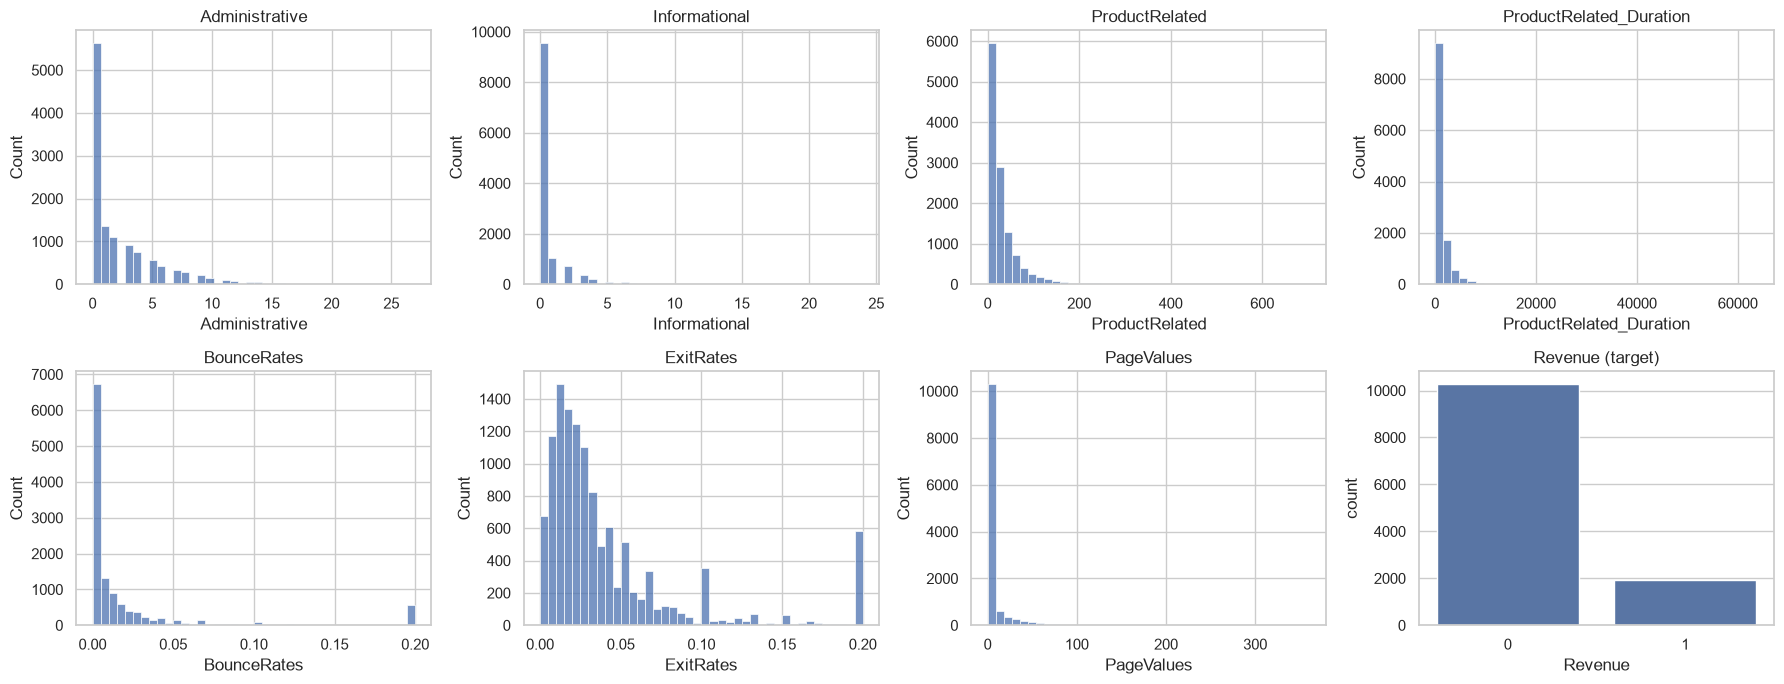

In [6]:
# Univariate
num_feats = ["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration",
             "BounceRates", "ExitRates", "PageValues"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_feats):
    sns.histplot(df[c], bins=40, ax=ax); ax.set_title(c)
sns.countplot(data=df, x="Revenue", ax=axes.ravel()[-1]); axes.ravel()[-1].set_title("Revenue (target)")
plt.tight_layout(); plt.show()

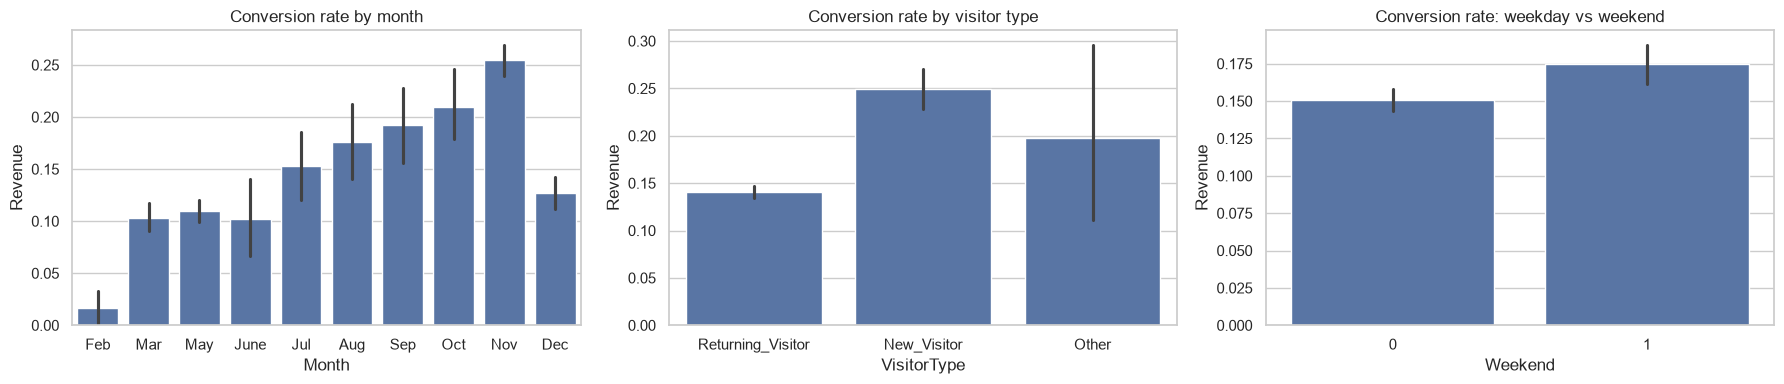

In [7]:
# Bivariate: conversion rate by category
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
order = ["Feb","Mar","May","June","Jul","Aug","Sep","Oct","Nov","Dec"]
sns.barplot(data=df, x="Month", y="Revenue", order=[m for m in order if m in df.Month.unique()], ax=axes[0]); axes[0].set_title("Conversion rate by month")
sns.barplot(data=df, x="VisitorType", y="Revenue", ax=axes[1]); axes[1].set_title("Conversion rate by visitor type")
sns.barplot(data=df, x="Weekend", y="Revenue", ax=axes[2]); axes[2].set_title("Conversion rate: weekday vs weekend")
plt.tight_layout(); plt.show()

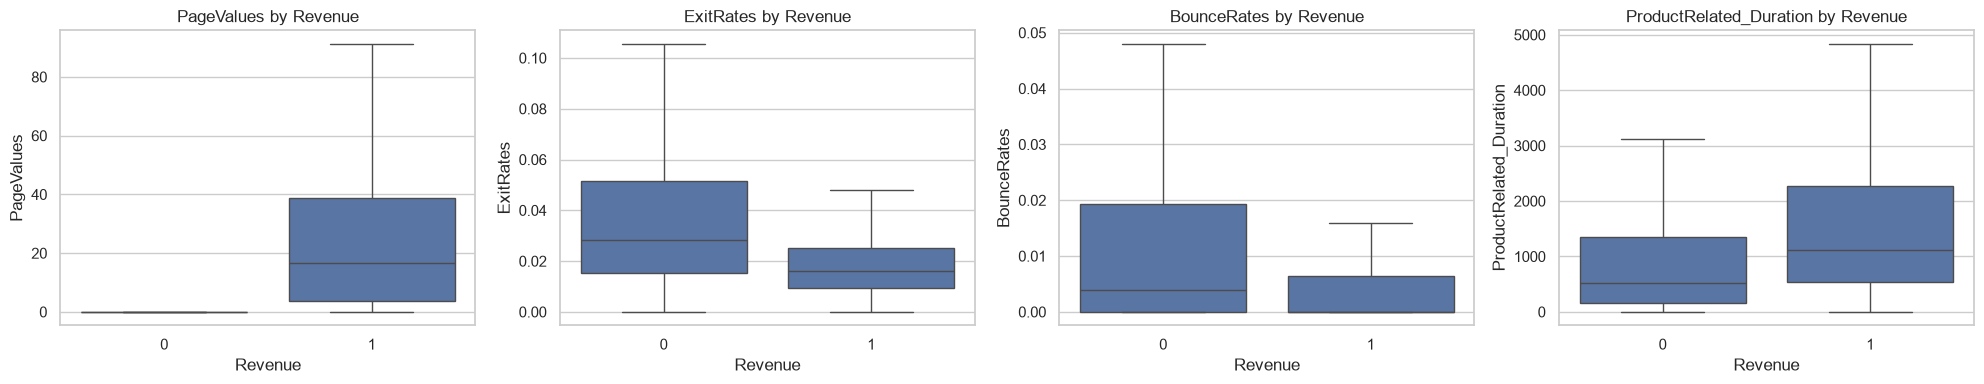

In [8]:
# Bivariate: numeric features vs target
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]):
    sns.boxplot(data=df, x="Revenue", y=c, ax=ax, showfliers=False); ax.set_title(f"{c} by Revenue")
plt.tight_layout(); plt.show()

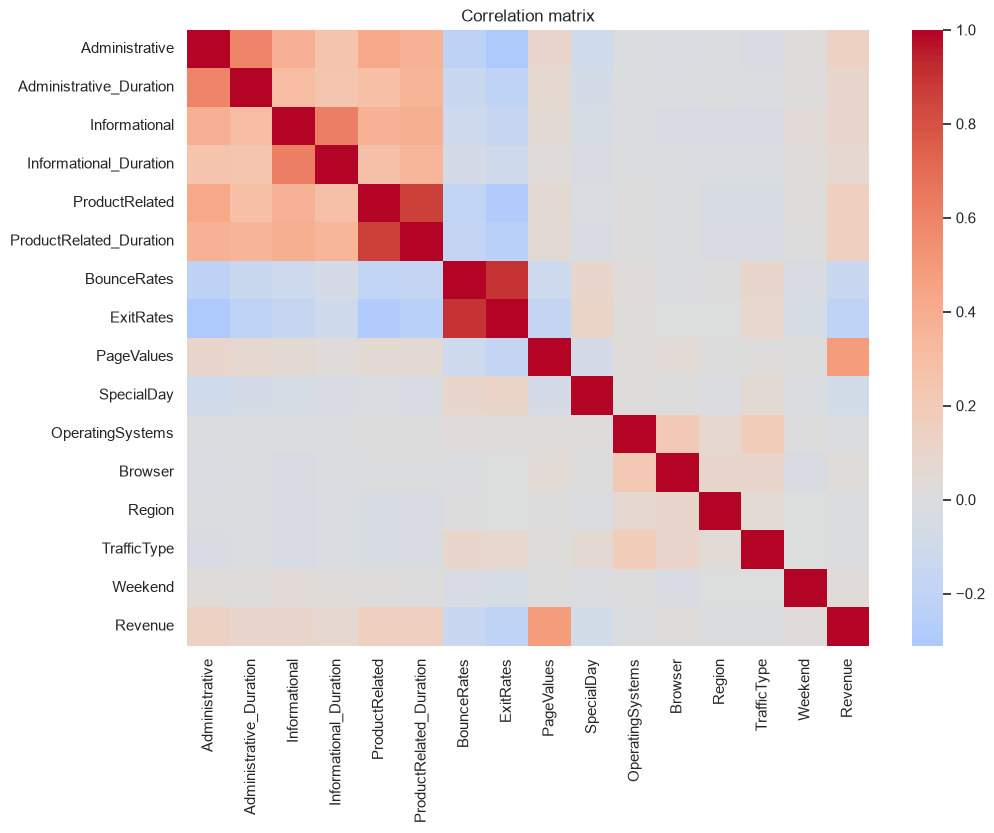

Revenue                    1.000
PageValues                 0.492
ProductRelated             0.156
ProductRelated_Duration    0.150
Administrative             0.136
Informational              0.094
Administrative_Duration    0.092
Informational_Duration     0.069
Weekend                    0.028
Browser                    0.024
TrafficType               -0.006
Region                    -0.013
OperatingSystems          -0.015
SpecialDay                -0.084
BounceRates               -0.145
ExitRates                 -0.204
Name: Revenue, dtype: float64


In [9]:
# Multivariate: correlation heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix"); plt.show()
print(df.select_dtypes("number").corr()["Revenue"].sort_values(ascending=False).round(3))

### EDA insights
1. The target distribution shows that purchase sessions are the minority class, so accuracy alone would hide poor buyer detection.
2. Compare `PageValues` for buyers and non-buyers; it is a useful signal, but can reflect pages viewed later in a session and should not be treated as an early-session feature.
3. The conversion-rate charts by month and visitor type show where intent differs across sessions; the groups are descriptive, not evidence that these characteristics cause purchases.
4. Page counts and durations are skewed, while bounce and exit rates capture separate engagement patterns; the pipeline scales numeric inputs and derives total pages, average time per page, and product-page share.
5. The multivariate view helps spot overlapping signals, but feature importance and test-set results—not visual correlation alone—are used to assess predictive value.

## 4 · Feature engineering and preprocessing (inside a Pipeline, split first)

In [10]:
%%writefile features.py
import numpy as np
import pandas as pd

CAT_COLS = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]

def add_features(X):
    X = X.copy()
    X["TotalPages"] = X["Administrative"] + X["Informational"] + X["ProductRelated"]
    X["TotalDuration"] = X["Administrative_Duration"] + X["Informational_Duration"] + X["ProductRelated_Duration"]
    pages = X["TotalPages"].replace(0, np.nan)
    X["AvgTimePerPage"] = (X["TotalDuration"] / pages).fillna(0)
    X["ProductShare"] = (X["ProductRelated"] / pages).fillna(0)
    X["HasPageValue"] = (X["PageValues"] > 0).astype(int)
    X["Weekend"] = X["Weekend"].astype(int)
    for c in CAT_COLS:
        X[c] = X[c].astype(str)
    return X

Overwriting features.py


In [11]:
from features import add_features, CAT_COLS

X = df.drop(columns="Revenue")
y = df["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, "| train conv.:", round(y_train.mean(), 3), "| test conv.:", round(y_test.mean(), 3))

num_cols = [c for c in add_features(X_train.head()).columns if c not in CAT_COLS]

def make_pipe(model):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])
    return Pipeline([("fe", FunctionTransformer(add_features)), ("pre", pre), ("model", model)])

(9764, 17) (2441, 17) | train conv.: 0.156 | test conv.: 0.156


## 5 · Modeling: baseline + 3 algorithms (5-fold stratified CV on the training set)

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "f1": "f1"}
rows = []
for name, m in models.items():
    r = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}})
cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

,roc_auc,pr_auc,recall,f1
model,,,,
Baseline (majority),0.500,0.156,0.000,0.000
Logistic Regression,0.918,0.667,0.824,0.644
Random Forest,0.929,0.743,0.748,0.684
Gradient Boosting,0.930,0.742,0.589,0.648


## 6 · Hyperparameter tuning (RandomizedSearchCV, training data only, scoring = PR-AUC)

In [13]:
param_grids = {
    "Logistic Regression": {"model__C": np.logspace(-3, 2, 20)},
    "Random Forest": {"model__n_estimators": [200, 300, 500], "model__max_depth": [None, 6, 10, 16],
                      "model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.3, 0.5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.05, 0.1],
                          "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.85, 1.0]},
}
searches = {}
for name, grid in param_grids.items():
    s = RandomizedSearchCV(make_pipe(models[name]), grid, n_iter=12, scoring="average_precision",
                           cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f"{name}: best CV PR-AUC = {s.best_score_:.3f} | {s.best_params_}")
best_name = max(searches, key=lambda k: searches[k].best_score_)
best_pipe = searches[best_name].best_estimator_
print("\nBest model:", best_name)

Logistic Regression: best CV PR-AUC = 0.674 | {'model__C': np.float64(0.006158482110660267)}
Random Forest: best CV PR-AUC = 0.753 | {'model__n_estimators': 500, 'model__min_samples_leaf': 5, 'model__max_features': 0.3, 'model__max_depth': 6}
Gradient Boosting: best CV PR-AUC = 0.753 | {'model__subsample': 0.7, 'model__n_estimators': 100, 'model__max_depth': 4, 'model__learning_rate': 0.03}

Best model: Random Forest


## 7 · Choosing the decision threshold (on training data only)
The business wants to **catch buyers** (recall) while not wasting coupons. We use **F2** (recall counts more than precision) and pick the threshold on **out-of-fold** training predictions, so the test set stays untouched.

Chosen threshold (max F2 on out-of-fold train): 0.44


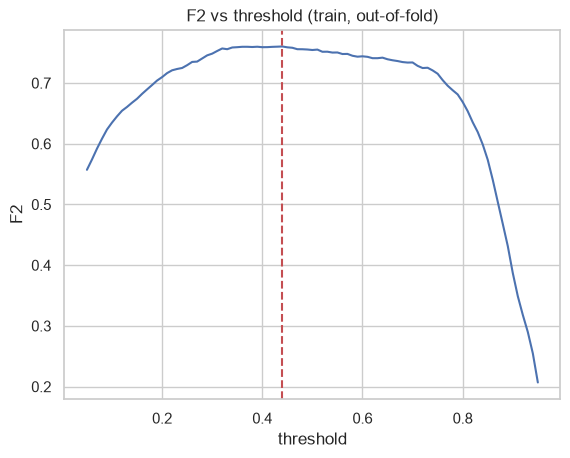

In [14]:
oof = cross_val_predict(make_pipe(searches[best_name].best_estimator_.named_steps["model"]), X_train, y_train,
                        cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
grid_t = np.linspace(0.05, 0.95, 91)
f2 = [fbeta_score(y_train, oof >= t, beta=2) for t in grid_t]
THRESHOLD = float(grid_t[int(np.argmax(f2))])
print("Chosen threshold (max F2 on out-of-fold train):", round(THRESHOLD, 2))
plt.plot(grid_t, f2); plt.axvline(THRESHOLD, color="r", ls="--"); plt.xlabel("threshold"); plt.ylabel("F2"); plt.title("F2 vs threshold (train, out-of-fold)"); plt.show()

## 8 · Final evaluation on the untouched test set

In [15]:
rows = []
curves = {}
for name, s in searches.items():
    p = s.best_estimator_.predict_proba(X_test)[:, 1]
    curves[name] = p
    rows.append({"model": name, "roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p)})
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
rows.append({"model": "Baseline (majority)", "roc_auc": 0.5, "pr_auc": float(y_test.mean())})
test_scores = pd.DataFrame(rows).set_index("model").round(3)
test_scores

,roc_auc,pr_auc
model,,
Logistic Regression,0.927,0.702
Random Forest,0.936,0.749
Gradient Boosting,0.937,0.755
Baseline (majority),0.500,0.156


Best model: Random Forest | threshold = 0.44
              precision    recall  f1-score   support

 No purchase       0.97      0.85      0.91      2059
    Purchase       0.52      0.88      0.65       382

    accuracy                           0.85      2441
   macro avg       0.75      0.86      0.78      2441
weighted avg       0.90      0.85      0.87      2441

ROC-AUC: 0.936 | PR-AUC: 0.749


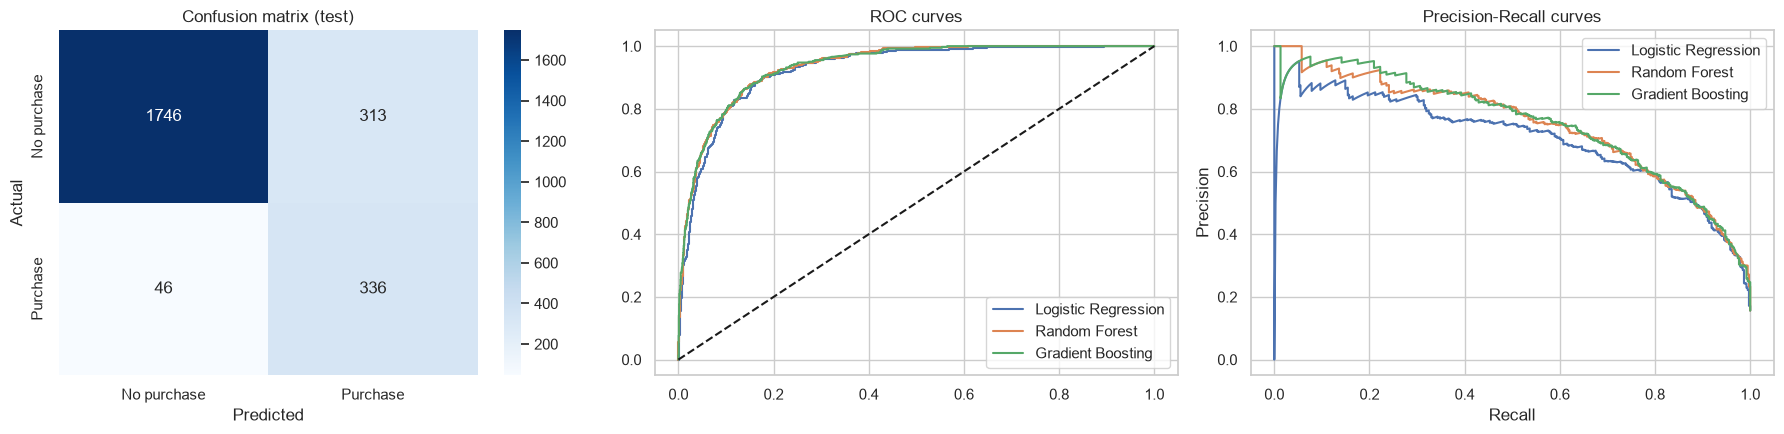

In [16]:
p_best = curves[best_name]
pred = (p_best >= THRESHOLD).astype(int)
print(f"Best model: {best_name} | threshold = {THRESHOLD:.2f}")
print(classification_report(y_test, pred, target_names=["No purchase", "Purchase"]))
print("ROC-AUC:", round(roc_auc_score(y_test, p_best), 3), "| PR-AUC:", round(average_precision_score(y_test, p_best), 3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No purchase", "Purchase"], yticklabels=["No purchase", "Purchase"])
axes[0].set_title("Confusion matrix (test)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
for n, p in curves.items():
    fpr, tpr, _ = roc_curve(y_test, p); axes[1].plot(fpr, tpr, label=n)
    pr, rc, _ = precision_recall_curve(y_test, p); axes[2].plot(rc, pr, label=n)
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curves"); axes[1].legend()
axes[2].set_title("Precision-Recall curves"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()
plt.tight_layout(); plt.show()

## 9 · Error analysis and feature importance

In [17]:
err = X_test.copy()
err["actual"] = y_test.values; err["pred"] = pred; err["proba"] = p_best
err["error"] = np.where((err.actual == 1) & (err.pred == 0), "missed buyer (FN)",
                np.where((err.actual == 0) & (err.pred == 1), "false alarm (FP)", "correct"))
print(err["error"].value_counts())
print("\nError rate by VisitorType:"); print((err.error != "correct").groupby(err.VisitorType).mean().round(3))
print("\nMissed buyers: share with PageValues == 0:", round((err[err.error.str.startswith("missed")].PageValues == 0).mean(), 3))

error
correct              2082
false alarm (FP)      313
missed buyer (FN)      46
Name: count, dtype: int64

Error rate by VisitorType:
VisitorType
New_Visitor          0.105
Other                0.077
Returning_Visitor    0.155
Name: error, dtype: float64

Missed buyers: share with PageValues == 0: 1.0


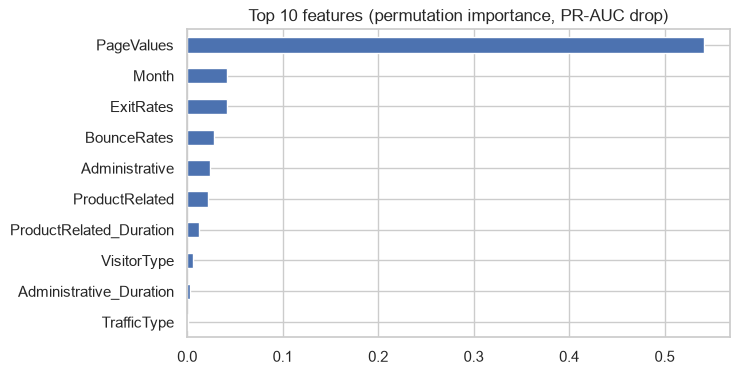

In [18]:
r = permutation_importance(best_pipe, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot.barh(figsize=(7, 4), title="Top 10 features (permutation importance, PR-AUC drop)"); plt.show()

## 10 · Stretch goal: top-10% likely-to-leave coupon campaign simulation
Visitors with the lowest predicted purchase probability are treated as the most likely to leave. The campaign targets exactly the bottom 10% of test-session scores. Coupon conversion uplift is an explicit assumption, not a causal result; a randomized A/B test is needed to measure actual incremental sales.

In [19]:
SURE_BUY = 0.70  # Above this estimated purchase probability, do not offer a coupon
CAMPAIGN_SHARE = 0.10
ASSUMED_UPLIFT = 0.05  # Assumption: fraction of targeted non-buyers converted by the coupon
campaign_size = int(np.ceil(len(p_best) * CAMPAIGN_SHARE))
likely_to_leave = np.argsort(p_best)[:campaign_size]
non_buyers_targeted = int((y_test.iloc[likely_to_leave] == 0).sum())
expected_extra_sales = non_buyers_targeted * ASSUMED_UPLIFT
print(f"Couponed visitors: {campaign_size} of {len(y_test)} ({campaign_size / len(y_test):.1%})")
print(f"Observed non-buyers in the targeted group: {non_buyers_targeted}")
print(f"Estimated extra sales at an assumed {ASSUMED_UPLIFT:.0%} coupon conversion uplift: {expected_extra_sales:.1f}")

Couponed visitors: 245 of 2441 (10.0%)
Observed non-buyers in the targeted group: 245
Estimated extra sales at an assumed 5% coupon conversion uplift: 12.2


## 11 · Save the final pipeline for the web app

In [20]:
artifact = {
    "pipeline": best_pipe,
    "model_name": best_name,
    "threshold": THRESHOLD,
    "sure_buy": SURE_BUY,
    "metrics": {
        "roc_auc": float(roc_auc_score(y_test, p_best)),
        "pr_auc": float(average_precision_score(y_test, p_best)),
        "recall": float(recall_score(y_test, pred)),
        "precision": float(precision_score(y_test, pred)),
        "f1": float(f1_score(y_test, pred)),
    },
    "defaults": {"OperatingSystems": int(X_train.OperatingSystems.mode()[0]), "Browser": int(X_train.Browser.mode()[0]),
                 "Region": int(X_train.Region.mode()[0]), "TrafficType": int(X_train.TrafficType.mode()[0])},
}
joblib.dump(artifact, "model.joblib")
print({k: round(v, 3) for k, v in artifact["metrics"].items()})

{'roc_auc': 0.936, 'pr_auc': 0.749, 'recall': 0.88, 'precision': 0.518, 'f1': 0.652}


## 12 · Business insight and limitations
- **What the results mean:** use the held-out test-set table and classification report above to assess ranking quality (ROC-AUC / PR-AUC) and the recall/precision trade-off at the training-selected threshold.
- **What the company should do:** offer a chat assistant to low-intent visitors, a coupon to visitors above the purchase threshold but below the sure-buy cutoff, and no incentive to likely buyers.
- **Campaign estimate:** the top-10% simulation estimates possible extra sales under the stated uplift assumption; it is not measured coupon impact or guaranteed revenue.
- **Limitations:** `PageValues` depends on pages already viewed, so predictions are more appropriate later in a session; data comes from one retailer and one year; test any coupon strategy with a randomized A/B test and monitor for drift.

**Dataset credit:** Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/468